# 3. Convex sets

Portfolio exercises 3.1–3.3. The tool of 3.1 is a segment tester: given a
membership test for a set $C$ and two points $x,y$, it samples
$x_\lambda=\lambda x+(1-\lambda)y$ for $\lambda\in[0,1]$ and reports every
sample that falls outside $C$. Every set is then checked twice: on random pairs
drawn from $C$, and on a deterministic witness pair for the sets that are
supposed to fail. Sections 3.2 and 3.3 use [CO 3.1]–[CO 3.2] (intersections
and affine maps preserve convexity) and [CO 4.7]–[CO 4.9] (ellipsoids, norm
balls, the cone of positive semidefinite matrices). All random experiments use
rng = np.random.default_rng(2026).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

## 3.1 Convexity test with segments [CO 3.1, 3.2]

### Task

Write a function that samples pairs of points $x,y$ of a 2-D set $C$ (given as
a membership test) and checks whether $\lambda x+(1-\lambda)y\in C$ for
$\lambda\in[0,1]$. Plot the set and, in red, the segments that leave it. Test:
a disc, an annulus, a crescent, the union of two discs and the intersection of
two discs.

### Explain

Which sets fail and why? Use your tool to illustrate [CO 3.1]: why is an
intersection of convex sets convex, but not a union?

In [2]:
def segment_violations(membership, x, y, n=2001):
    """Sample lam in [0, 1] on the segment [x, y] and report where it leaves C.

    membership maps an (N, d) array of points to a boolean (N,) array.
    Returns (lam, pts, outside), outside[i] True iff pts[i] is not in C.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    lam = np.linspace(0.0, 1.0, n)
    pts = lam[:, None] * x + (1.0 - lam)[:, None] * y
    return lam, pts, ~membership(pts)


def disc(c, r):
    """Closed disc {p : ||p - c||_2 <= r}, as a membership test."""
    c = np.asarray(c, dtype=float)
    return lambda p: np.linalg.norm(np.atleast_2d(p) - c, axis=1) <= r


def annulus(p, r_in=0.5, r_out=1.0):
    """Annulus {r_in <= ||p||_2 <= r_out}."""
    d = np.linalg.norm(np.atleast_2d(p), axis=1)
    return (r_in <= d) & (d <= r_out)


def crescent(p, r_out=1.0, c_in=(0.5, 0.0), r_in=0.5):
    """Disc of radius r_out with the disc (c_in, r_in) removed."""
    p = np.atleast_2d(p)
    d_out = np.linalg.norm(p, axis=1)
    d_in = np.linalg.norm(p - np.asarray(c_in, dtype=float), axis=1)
    return (d_out <= r_out) & (d_in > r_in)


C_LEFT, C_RIGHT = disc((-0.5, 0.0), 0.4), disc((0.5, 0.0), 0.4)   # disjoint
LENS_L, LENS_R = disc((-0.4, 0.0), 0.6), disc((0.4, 0.0), 0.6)    # overlapping

SETS_31 = {
    "disc":         disc((0.0, 0.0), 1.0),
    "annulus":      annulus,
    "crescent":     crescent,
    "union":        lambda p: C_LEFT(p) | C_RIGHT(p),
    "intersection": lambda p: LENS_L(p) & LENS_R(p),
}

# deterministic witnesses: both endpoints in C, midpoint expected outside
WITNESS_31 = {
    "annulus":  ((1.0, 0.0), (-1.0, 0.0)),
    "crescent": ((0.49, 0.8487), (0.49, -0.8487)),
    "union":    ((-0.5, 0.0), (0.5, 0.0)),
}
for name, (x, y) in WITNESS_31.items():
    assert SETS_31[name](np.array([x, y])).all(), f"{name}: witness endpoint outside C"
print("witness endpoints all inside their sets")

witness endpoints all inside their sets


In [3]:
def sample_inside(membership, lo=-1.3, hi=1.3, n=241):
    """Fine grid of points of C, used as the pool the pairs are drawn from."""
    g = np.linspace(lo, hi, n)
    P = np.array([(u, v) for u in g for v in g])
    return P[membership(P)]


N_PAIRS = 300
print(f"{'set':<14}{'points in C':>12}{'pairs':>7}{'failing':>9}{'fraction':>10}")
for name, membership in SETS_31.items():
    P = sample_inside(membership)
    bad = 0
    for _ in range(N_PAIRS):
        x, y = P[rng.integers(len(P))], P[rng.integers(len(P))]
        _, _, outside = segment_violations(membership, x, y)
        bad += int(outside.any())
    print(f"{name:<14}{len(P):>12}{N_PAIRS:>7}{bad:>9}{bad / N_PAIRS:>10.3f}")

print()
print("deterministic witnesses (both endpoints in C):")
for name, (x, y) in WITNESS_31.items():
    membership = SETS_31[name]
    lam, pts, outside = segment_violations(membership, x, y)
    mid = 0.5 * (np.asarray(x, dtype=float) + np.asarray(y, dtype=float))
    print(f"  {name:<10} outside C for {lam[outside].min():.3f} <= lambda <= "
          f"{lam[outside].max():.3f}; midpoint {np.round(mid, 4)} in C: "
          f"{bool(membership(mid[None])[0])}")

union_overlap = lambda p: LENS_L(p) | LENS_R(p)
top_l, top_r = np.array([-0.4, 0.6]), np.array([0.4, 0.6])
mid = 0.5 * (top_l + top_r)
d_mid = np.linalg.norm(mid - np.array([-0.4, 0.0]))
print()
print(f"overlapping discs, radius 0.6, centres (+-0.4, 0): both top points are in")
print(f"A u B, the midpoint {mid} is at distance {d_mid:.4f} from either centre")
print(f"and {d_mid:.4f} > 0.6, so the midpoint is outside A u B")
assert union_overlap(np.array([top_l, top_r])).all()
assert not union_overlap(mid[None])[0]

set            points in C  pairs  failing  fraction
disc                 26773    300        0     0.000
annulus              20068    300      157     0.523
crescent             20078    300       61     0.203
union                 8564    300      162     0.540
intersection          2115    300        0     0.000

deterministic witnesses (both endpoints in C):
  annulus    outside C for 0.251 <= lambda <= 0.750; midpoint [0. 0.] in C: False
  crescent   outside C for 0.206 <= lambda <= 0.794; midpoint [0.49 0.  ] in C: False
  union      outside C for 0.401 <= lambda <= 0.600; midpoint [0. 0.] in C: False

overlapping discs, radius 0.6, centres (+-0.4, 0): both top points are in
A u B, the midpoint [0.  0.6] is at distance 0.7211 from either centre
and 0.7211 > 0.6, so the midpoint is outside A u B


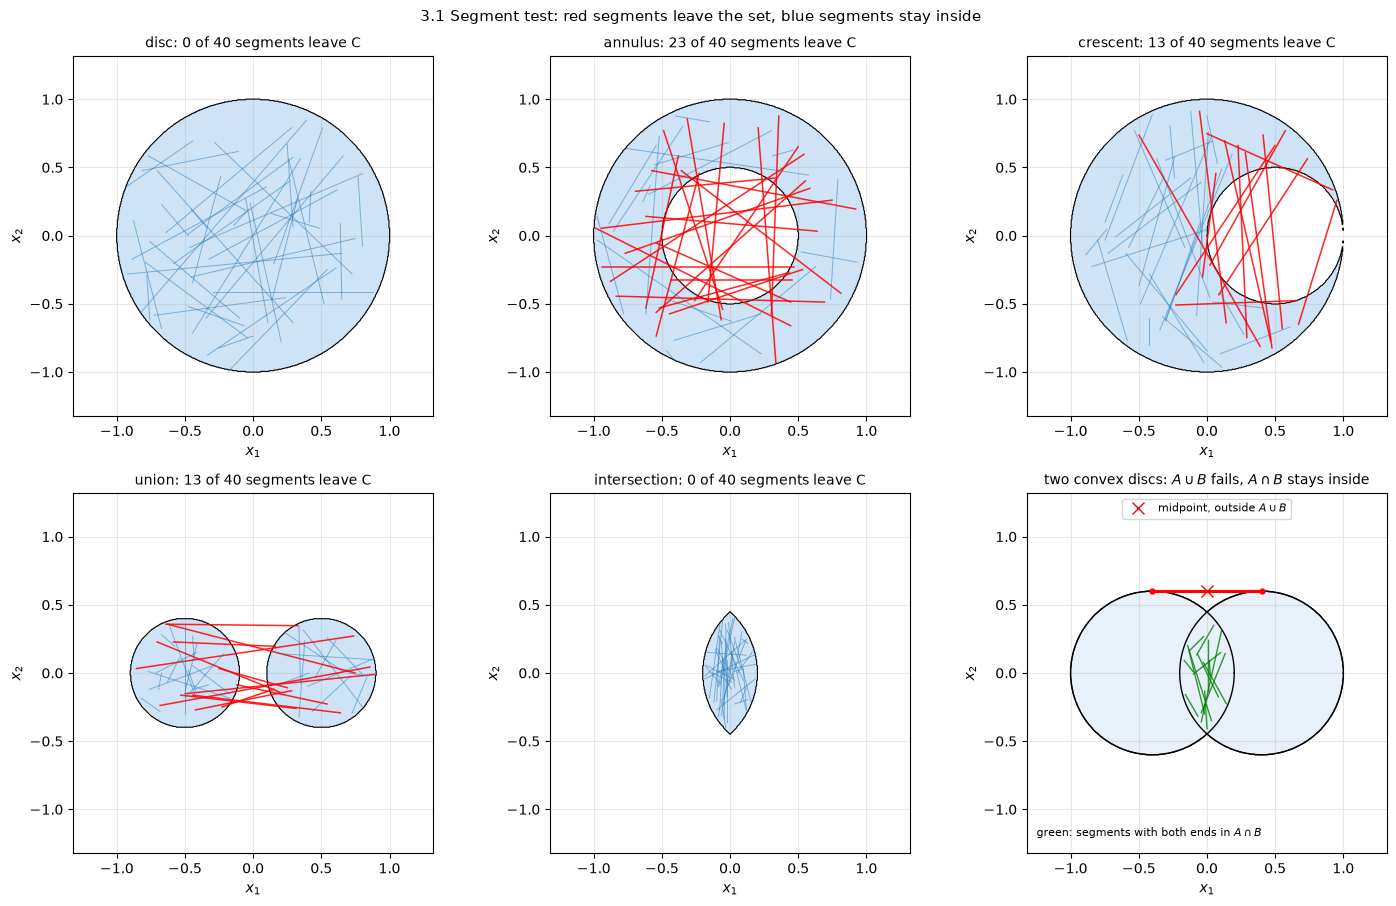

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 9.2))
gl = np.linspace(-1.3, 1.3, 501)
XXl, YYl = np.meshgrid(gl, gl)
GRIDL = np.column_stack([XXl.ravel(), YYl.ravel()])


def shade_2d(ax, membership, color="#cfe3f7"):
    inside = membership(GRIDL).reshape(XXl.shape).astype(float)
    ax.contourf(XXl, YYl, inside, levels=[0.5, 1.5], colors=[color])
    ax.contour(XXl, YYl, inside, levels=[0.5], colors="k", linewidths=0.8)


for ax, name in zip(axes.ravel(), SETS_31):
    membership = SETS_31[name]
    shade_2d(ax, membership)
    P = sample_inside(membership)
    n_bad = 0
    for _ in range(40):
        x, y = P[rng.integers(len(P))], P[rng.integers(len(P))]
        lam, pts, outside = segment_violations(membership, x, y, 601)
        if outside.any():
            n_bad += 1
            ax.plot(pts[:, 0], pts[:, 1], color="red", lw=1.1, alpha=0.85)
        else:
            ax.plot(pts[:, 0], pts[:, 1], color="#1f77b4", lw=0.7, alpha=0.5)
    ax.set_title(f"{name}: {n_bad} of 40 segments leave C", fontsize=10)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_xlim(-1.32, 1.32); ax.set_ylim(-1.32, 1.32); ax.set_aspect("equal")

ax = axes[1, 2]
shade_2d(ax, union_overlap, color="#e8f0fa")
th = np.linspace(0.0, 2 * np.pi, 400)
for c in ((-0.4, 0.0), (0.4, 0.0)):
    ax.plot(c[0] + 0.6 * np.cos(th), c[1] + 0.6 * np.sin(th), "k", lw=1.0)
lens_pool = sample_inside(lambda p: LENS_L(p) & LENS_R(p), lo=-1.0, hi=1.0)
for _ in range(14):
    x = lens_pool[rng.integers(len(lens_pool))]
    y = lens_pool[rng.integers(len(lens_pool))]
    ax.plot([x[0], y[0]], [x[1], y[1]], color="green", lw=1.0, alpha=0.8)
ax.plot([top_l[0], top_r[0]], [top_l[1], top_r[1]], "r-", lw=2.2)
ax.plot([top_l[0], top_r[0]], [top_l[1], top_r[1]], "r.", ms=7)
ax.plot([0.0], [0.6], "rx", ms=9, label="midpoint, outside $A\\cup B$")
ax.set_title("two convex discs: $A\\cup B$ fails, $A\\cap B$ stays inside", fontsize=10)
ax.text(-1.25, -1.2, "green: segments with both ends in $A\\cap B$", fontsize=8)
ax.legend(loc="upper center", fontsize=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_xlim(-1.32, 1.32); ax.set_ylim(-1.32, 1.32); ax.set_aspect("equal")

fig.suptitle("3.1 Segment test: red segments leave the set, blue segments stay inside",
             fontsize=11)
fig.tight_layout()
plt.show()

### Explain

**Which sets fail.** Only the disc and the intersection survive: 0 of the 300
random pairs left the disc and 0 of 300 left the lens, and the 40 pairs drawn
in those two panels also stayed inside. The annulus failed on 157 of 300 pairs
(0.523), the crescent on 61 of 300 (0.203) and the union of the two disjoint
discs on 162 of 300 (0.540). The rates are below 1 because a chord leaves the
set only when it crosses the missing piece: in the crescent the removed disc at
$(1/2,0)$ bites into one side, and most chords miss it, which is why its rate
is the smallest.

**Why they fail.** Each failing set has a hole or a gap, and one chord through
it is enough:

- annulus $\{1/2\le\|x\|_2\le1\}$: $(1,0)$ and $(-1,0)$ are both in $C$, but the
  midpoint is the origin, at distance $0<1/2$ from the centre. The tool reports
  the segment outside $C$ for $0.251\le\lambda\le0.750$, the chord through the
  hole.
- crescent (unit disc minus the disc of radius $1/2$ at $(1/2,0)$): the horns
  $(0.49,\pm0.8487)$ are at distance $0.8487>1/2$ from $(1/2,0)$, so both are in
  $C$; their midpoint $(0.49,0)$ is at distance $0.01<1/2$, inside the removed
  disc. The segment is outside $C$ for $0.206\le\lambda\le0.794$.
- union of the discs of radius $0.4$ at $(\pm0.5,0)$: the two centres are in
  $C$, but their midpoint $(0,0)$ is at distance $0.5>0.4$ from both centres, so
  it is in neither disc. The segment is outside $C$ for $0.401\le\lambda\le0.600$.

**Intersection versus union [CO 3.1].** If $C_1,C_2$ are convex and
$x,y\in C_1\cap C_2$, then $x,y\in C_1$ and $x,y\in C_2$; convexity of each set
gives $\lambda x+(1-\lambda)y\in C_1$ and $\lambda x+(1-\lambda)y\in C_2$, hence
the point is in $C_1\cap C_2$. The argument uses both sets on the *same* pair
of points, which is exactly what an intersection allows.

A union does not: $x\in C_1\setminus C_2$ and $y\in C_2\setminus C_1$ is
allowed, and then no single convexity hypothesis applies to the pair. The last
panel makes this sharp with two *overlapping* convex discs, $A$ at $(-0.4,0)$
and $B$ at $(0.4,0)$, both of radius $0.6$. Their tops $(-0.4,0.6)\in A$ and
$(0.4,0.6)\in B$ are both in $A\cup B$, but the midpoint $(0,0.6)$ is at
distance $0.7211>0.6$ from both centres, so it is outside $A\cup B$; the green
segments, with both ends in the lens $A\cap B$, all stay inside. Overlapping is
therefore not enough: the union of two convex sets is convex only when every
segment joining a point of one to a point of the other stays in the union, as
it does for instance when $C_1\subseteq C_2$.

## 3.2 Examples of convex sets [CO 3.2, 4.7, 4.8]

### Task

Plot in 2-D (and, where easy, in 3-D): a halfspace $\{a^Tx\le b\}$, a
polyhedron $\{Ax\le b\}$, the simplex $\{x\ge0,\ 1^Tx=1\}$ in $\mathbb{R}^3$,
the convex hull of random points (scipy.spatial.ConvexHull), an ellipsoid
$\{\tfrac12 x^TQx+p^Tx+c\le1\}$, and the norm balls $\{\|x\|_p\le1\}$ for
$p=1,2,\infty$.

### Explore

Add the "ball" with $p=1/2$. Apply an affine map $x\mapsto Ax+d$ to each set
[CO 3.2]. Make $Q$ in the ellipsoid indefinite.

### Explain

Which of the sets are convex, and why does the $p=1/2$ "ball" fail? What
happens to the ellipsoid when $Q$ has a negative eigenvalue? (Link to Section 2
of the Linear Algebra portfolio.)

In [5]:
# halfspace {a^T x <= b}
a_hs, b_hs = np.array([1.0, 2.0]), 1.0
halfspace = lambda p: np.atleast_2d(p) @ a_hs <= b_hs

# polyhedron {A x <= b}: the pentagon with vertices
# (-0.9,-1), (1,-1), (1,0.2), (0.4,0.8), (-0.9,0.8)
A_poly = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0], [1.0, 1.0]])
b_poly = np.array([1.0, 0.8, 0.9, 1.0, 1.2])
polyhedron = lambda p: np.all(np.atleast_2d(p) @ A_poly.T <= b_poly + 1e-12, axis=1)

# convex hull of 40 random points
cloud = rng.uniform(-1.0, 1.0, size=(40, 2))
hull = ConvexHull(cloud)


def hull_membership(p):
    """Inside-test of the convex hull: all facet inequalities A z + b <= 0."""
    p = np.atleast_2d(p)
    return np.all(p @ hull.equations[:, :2].T + hull.equations[:, 2] <= 1e-12, axis=1)


# ellipsoid {1/2 x^T Q x + p^T x + c <= 1}, Q positive definite
Q_ell = np.array([[2.0, 0.6], [0.6, 1.2]])
p_ell = np.array([0.2, -0.3])
c_ell = -0.4


def quad_form(p, Q=Q_ell):
    p = np.atleast_2d(p)
    return np.einsum("ni,ij,nj->n", p, Q, p)


ellipsoid = lambda p: 0.5 * quad_form(p) + np.atleast_2d(p) @ p_ell + c_ell <= 1.0

eig_Qell = np.linalg.eigvalsh(Q_ell)
centre_ell = -np.linalg.solve(Q_ell, p_ell)
print("Q_ell symmetric:", np.allclose(Q_ell, Q_ell.T), " eigenvalues:", eig_Qell)
print("value at the centre", np.round(centre_ell, 4), "of the quadratic form:",
      round(float(0.5 * centre_ell @ Q_ell @ centre_ell + p_ell @ centre_ell + c_ell), 4))
assert np.all(eig_Qell > 0), "the ellipsoid needs Q positive definite"
assert ellipsoid(centre_ell[None])[0], "the centre must belong to the ellipsoid"

# norm balls {||x||_p <= 1}, and the p = 1/2 'ball'
def norm_ball(p, q):
    return np.sum(np.abs(np.atleast_2d(p)) ** q, axis=1) ** (1.0 / q) <= 1.0


ball_1 = lambda p: norm_ball(p, 1.0)
ball_2 = lambda p: norm_ball(p, 2.0)
ball_inf = lambda p: np.max(np.abs(np.atleast_2d(p)), axis=1) <= 1.0
ball_half = lambda p: norm_ball(p, 0.5)

# simplex {x >= 0, 1^T x = 1} in R^3
def simplex(p):
    p = np.atleast_2d(p)
    return np.all(p >= -1e-12, axis=1) & (np.abs(p.sum(axis=1) - 1.0) <= 1e-12)


A2 = np.array([[1.0, 0.35], [0.15, 0.9]])      # affine map used in the Explore
d2 = np.array([0.3, -0.1])
A3 = np.array([[1.0, 0.3, 0.0], [0.1, 0.9, 0.2], [0.0, 0.2, 1.1]])
d3 = np.array([0.3, -0.2, 0.5])


def affine_image(membership, A, d):
    """z is in A C + d iff A^{-1}(z - d) is in C."""
    A_inv = np.linalg.inv(A)
    return lambda z: membership((np.atleast_2d(z) - d) @ A_inv.T)


print("all norm balls defined; simplex(eye(3)) =", simplex(np.eye(3)).tolist())

Q_ell symmetric: True  eigenvalues: [0.87888974 2.32111026]
value at the centre [-0.2059  0.3529] of the quadratic form: -0.4735
all norm balls defined; simplex(eye(3)) = [True, True, True]


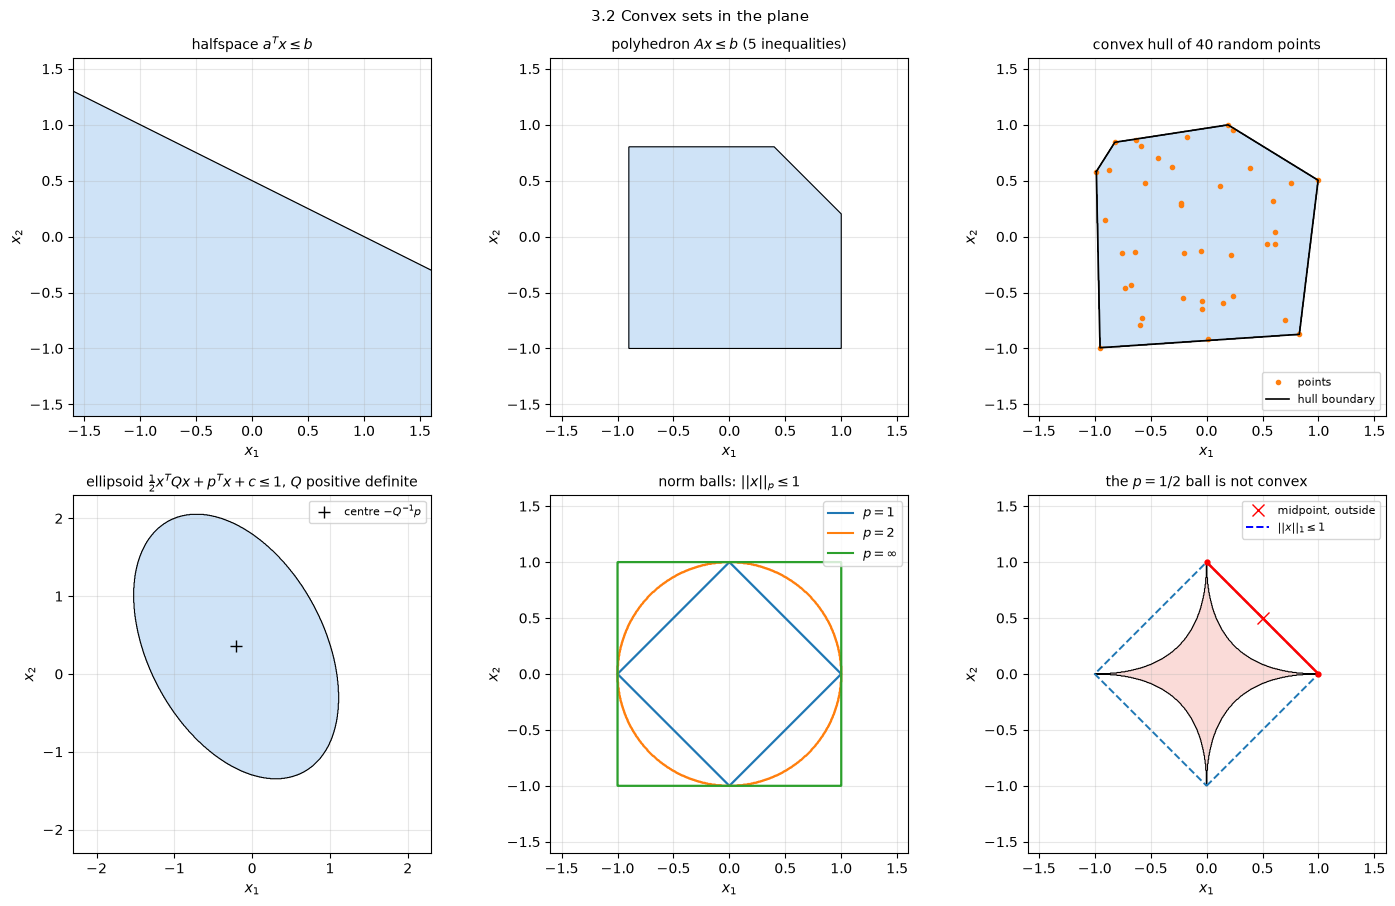

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 9.2))
g2 = np.linspace(-2.4, 2.4, 901)
XX2, YY2 = np.meshgrid(g2, g2)
GRID2 = np.column_stack([XX2.ravel(), YY2.ravel()])


def draw_2d(ax, membership, title, color="#cfe3f7"):
    inside = membership(GRID2).reshape(XX2.shape).astype(float)
    ax.contourf(XX2, YY2, inside, levels=[0.5, 1.5], colors=[color])
    ax.contour(XX2, YY2, inside, levels=[0.5], colors="k", linewidths=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")


draw_2d(axes[0, 0], halfspace, "halfspace $a^T x \\leq b$")
draw_2d(axes[0, 1], polyhedron, "polyhedron $A x \\leq b$ (5 inequalities)")

draw_2d(axes[0, 2], hull_membership, f"convex hull of {len(cloud)} random points")
axes[0, 2].plot(cloud[:, 0], cloud[:, 1], "o", ms=3, color="C1", label="points")
ring = np.vstack([cloud[hull.vertices], cloud[hull.vertices][:1]])
axes[0, 2].plot(ring[:, 0], ring[:, 1], "-", color="k", lw=1.2, label="hull boundary")
axes[0, 2].legend(loc="lower right", fontsize=8)

draw_2d(axes[1, 0], ellipsoid,
        "ellipsoid $\\frac{1}{2} x^T Q x + p^T x + c \\leq 1$, $Q$ positive definite")
axes[1, 0].plot(*centre_ell, "k+", ms=9, label="centre $-Q^{-1}p$")
axes[1, 0].legend(loc="upper right", fontsize=8)
axes[1, 0].set_xlim(-2.3, 2.3); axes[1, 0].set_ylim(-2.3, 2.3)

ax = axes[1, 1]
for membership, label, color in [(ball_1, "$p=1$", "C0"), (ball_2, "$p=2$", "C1"),
                                 (ball_inf, "$p=\\infty$", "C2")]:
    inside = membership(GRID2).reshape(XX2.shape).astype(float)
    ax.contour(XX2, YY2, inside, levels=[0.5], colors=[color], linewidths=1.6)
    ax.plot([], [], color=color, label=label)
ax.set_title("norm balls: $||x||_p \\leq 1$", fontsize=10)
ax.legend(fontsize=9); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

ax = axes[1, 2]
draw_2d(ax, ball_half, "the $p=1/2$ ball is not convex", color="#fadbd8")
inside1 = ball_1(GRID2).reshape(XX2.shape).astype(float)
ax.contour(XX2, YY2, inside1, levels=[0.5], colors="C0", linewidths=1.4,
           linestyles="--")
ax.plot([1.0, 0.0], [0.0, 1.0], "r-", lw=1.8)
ax.plot([1.0, 0.0], [0.0, 1.0], "r.", ms=7)
ax.plot([0.5], [0.5], "rx", ms=9, label="midpoint, outside")
ax.plot([], [], "b--", lw=1.4, label="$||x||_1 \\leq 1$")
ax.legend(loc="upper right", fontsize=8)

fig.suptitle("3.2 Convex sets in the plane", fontsize=11)
fig.tight_layout()
plt.show()

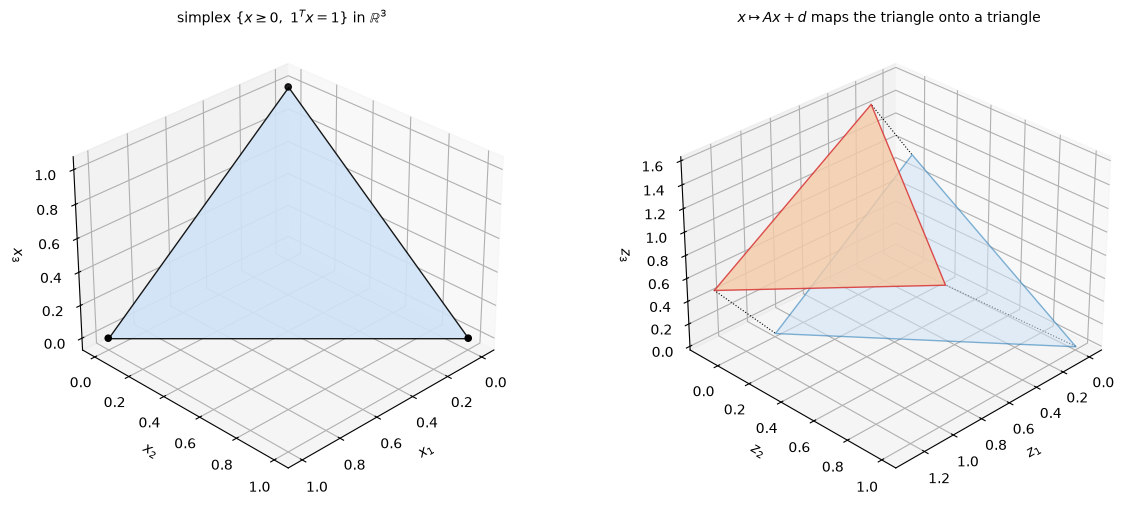

vertices map to vertices: True
image vertices: [[1.3, -0.1, 0.5], [0.6, 0.7, 0.7], [0.3, 0.0, 1.6]]


In [7]:
verts = np.eye(3)
img_verts = verts @ A3.T + d3
simplex_image = lambda z: simplex(np.linalg.solve(A3, (np.atleast_2d(z) - d3).T).T)

fig = plt.figure(figsize=(12.5, 5.2))
ax = fig.add_subplot(121, projection="3d")
ax.plot_trisurf(verts[:, 0], verts[:, 1], verts[:, 2], triangles=[[0, 1, 2]],
                color="#cfe3f7", alpha=0.9, edgecolor="k", shade=False)
ax.scatter(verts[:, 0], verts[:, 1], verts[:, 2], color="k")
ax.set_title("simplex $\\{x \\geq 0,\\ 1^T x = 1\\}$ in $\\mathbb{R}^3$", fontsize=10)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
ax.view_init(elev=30, azim=45)

ax = fig.add_subplot(122, projection="3d")
ax.plot_trisurf(verts[:, 0], verts[:, 1], verts[:, 2], triangles=[[0, 1, 2]],
                color="#cfe3f7", alpha=0.55, edgecolor="C0", shade=False)
ax.plot_trisurf(img_verts[:, 0], img_verts[:, 1], img_verts[:, 2],
                triangles=[[0, 1, 2]], color="#f5cba7", alpha=0.8, edgecolor="C3",
                shade=False)
for v, w in zip(verts, img_verts):
    ax.plot([v[0], w[0]], [v[1], w[1]], [v[2], w[2]], "k:", lw=0.8)
ax.set_title("$x\\mapsto Ax+d$ maps the triangle onto a triangle", fontsize=10)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.set_zlabel("$z_3$")
ax.view_init(elev=30, azim=45)
fig.tight_layout()
plt.show()

print("vertices map to vertices:", np.allclose(img_verts, verts @ A3.T + d3))
print("image vertices:", np.round(img_verts, 3).tolist())

In [8]:
def pool_inside(membership, dim=2, box=1.5, n=200_000):
    """Uniform points of a box, kept only where they belong to C."""
    P = rng.uniform(-box, box, size=(n, dim))
    return P[membership(P)]


def count_failing(membership, P, n_pairs=200, n=1001):
    """Number of random pairs from the pool whose segment leaves C."""
    bad = 0
    for _ in range(n_pairs):
        x, y = P[rng.integers(len(P))], P[rng.integers(len(P))]
        _, _, outside = segment_violations(membership, x, y, n)
        bad += int(outside.any())
    return bad


sets_32 = {
    "halfspace": halfspace, "polyhedron": polyhedron, "convex hull": hull_membership,
    "ellipsoid": ellipsoid, "$\\ell_1$ ball": ball_1, "$\\ell_2$ ball": ball_2,
    "$\\ell_\\infty$ ball": ball_inf, "$\\ell_{1/2}$ ball": ball_half,
}

print(f"{'set':<17}{'points':>8}{'pairs':>7}{'failing':>9}{'image fails':>13}")
for name, membership in sets_32.items():
    P = pool_inside(membership)
    print(f"{name:<17}{len(P):>8}{200:>7}{count_failing(membership, P):>9}"
          f"{count_failing(affine_image(membership, A2, d2), P @ A2.T + d2):>13}")

simplex_pool = rng.dirichlet(np.ones(3), size=20_000)
print(f"{'simplex in R^3':<17}{len(simplex_pool):>8}{200:>7}"
      f"{count_failing(simplex, simplex_pool):>9}"
      f"{count_failing(simplex_image, simplex_pool @ A3.T + d3):>13}")

# the affine identity behind [CO 3.2], checked on a random pair and lambda
x, y = rng.normal(size=2), rng.normal(size=2)
lam = 0.37
lhs = A2 @ (lam * x + (1 - lam) * y) + d2
rhs = lam * (A2 @ x + d2) + (1 - lam) * (A2 @ y + d2)
assert np.allclose(lhs, rhs)
print("\nA(lam x + (1-lam) y) + d = lam (Ax + d) + (1-lam)(Ay + d), residual",
      f"{np.abs(lhs - rhs).max():.2e}")

# the p = 1/2 witness: both ends on the boundary, midpoint outside
xw, yw = np.array([1.0, 0.0]), np.array([0.0, 1.0])
assert ball_half(np.array([xw, yw])).all()
print(f"\np = 1/2: sum sqrt|x_i| = {np.sqrt(1.0):.4f} at (1,0) and (0,1),"
      f" {2 * np.sqrt(0.5):.4f} at their midpoint (0.5,0.5) > 1")

set                points  pairs  failing  image fails
halfspace          133734    200        0            0
polyhedron          72033    200        0            0
convex hull         74128    200        0            0
ellipsoid          128639    200        0            0
$\ell_1$ ball       44575    200        0            0
$\ell_2$ ball       69941    200        0            0
$\ell_\infty$ ball   88865    200        0            0
$\ell_{1/2}$ ball   14803    200       13           16
simplex in R^3      20000    200        0            0

A(lam x + (1-lam) y) + d = lam (Ax + d) + (1-lam)(Ay + d), residual 1.11e-16

p = 1/2: sum sqrt|x_i| = 1.0000 at (1,0) and (0,1), 1.4142 at their midpoint (0.5,0.5) > 1


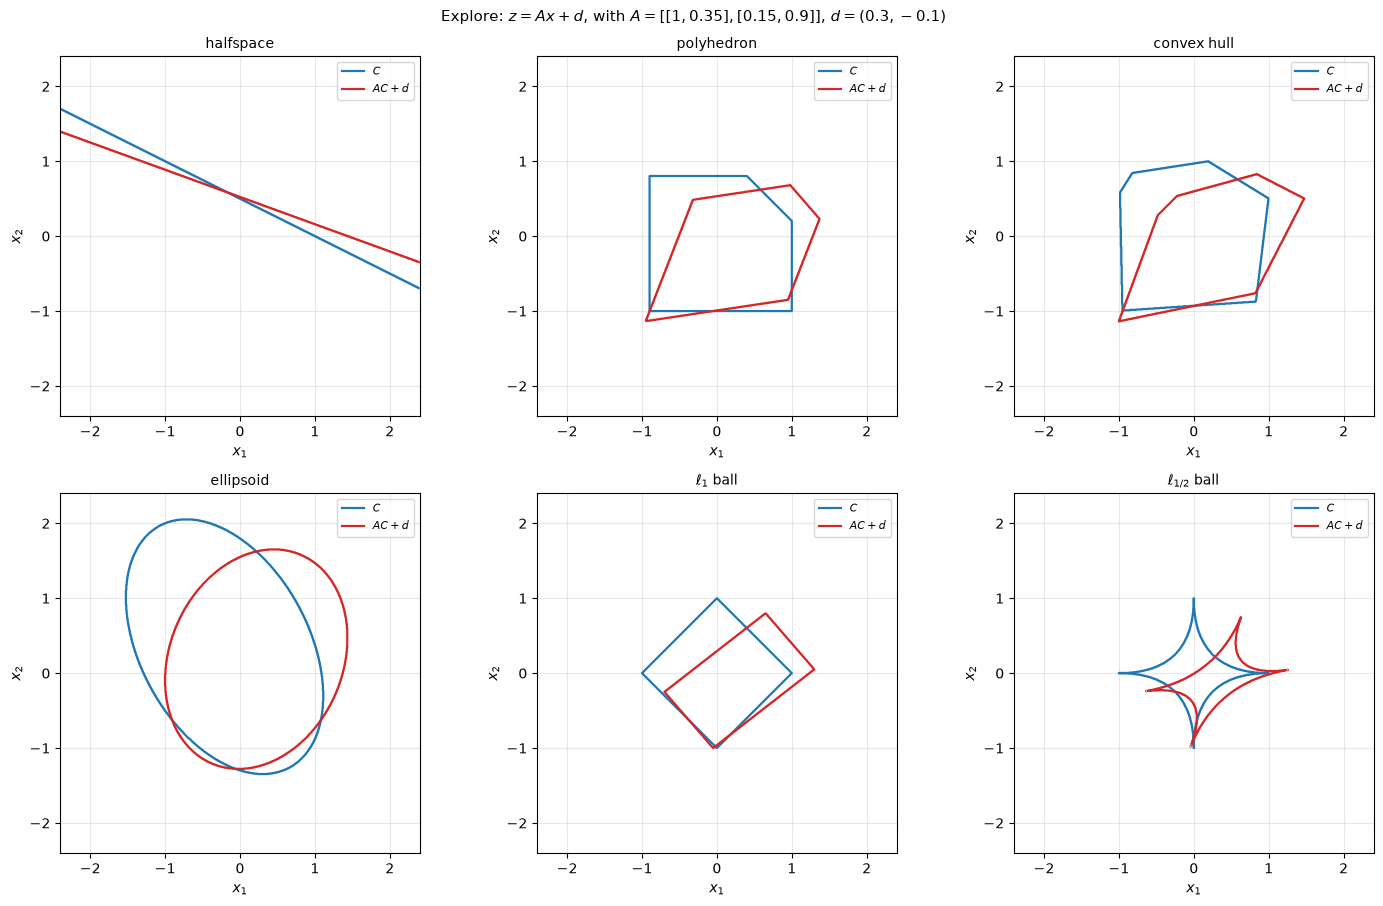

In [9]:
sets_img = {"halfspace": halfspace, "polyhedron": polyhedron,
            "convex hull": hull_membership, "ellipsoid": ellipsoid,
            "$\\ell_1$ ball": ball_1, "$\\ell_{1/2}$ ball": ball_half}

fig, axes = plt.subplots(2, 3, figsize=(14.5, 9.2))
for ax, (name, membership) in zip(axes.ravel(), sets_img.items()):
    for f, color, label in [(membership, "C0", "$C$"),
                            (affine_image(membership, A2, d2), "C3", "$AC+d$")]:
        inside = f(GRID2).reshape(XX2.shape).astype(float)
        ax.contour(XX2, YY2, inside, levels=[0.5], colors=[color], linewidths=1.6)
        ax.plot([], [], color=color, lw=1.6, label=label)
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
    ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

fig.suptitle("Explore: $z = Ax + d$, with $A=[[1,0.35],[0.15,0.9]]$, $d=(0.3,-0.1)$",
             fontsize=11)
fig.tight_layout()
plt.show()

eigenvalues of the indefinite Q: [-0.5  1. ]
quadratic form at the two points: [0.5 0.5]
quadratic form at their midpoint [3. 0.] : 4.5


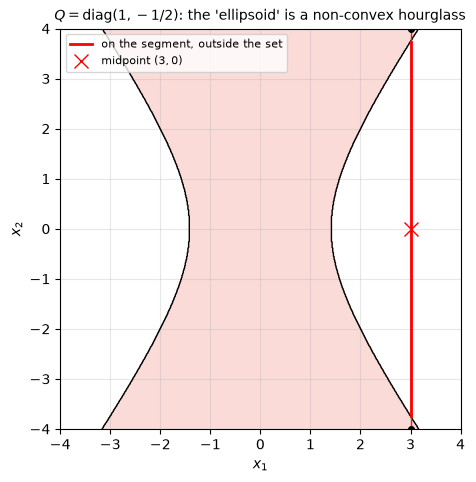

fraction of the segment that leaves the set: 0.935, and the set is unbounded along the x2 axis


In [10]:
Q_ind = np.array([[1.0, 0.0], [0.0, -0.5]])
eig_ind = np.linalg.eigvalsh(Q_ind)
print("eigenvalues of the indefinite Q:", eig_ind)
indef_set = lambda p: 0.5 * quad_form(p, Q_ind) <= 1.0     # x1^2 - x2^2/2 <= 2

xi, yi = np.array([3.0, 4.0]), np.array([3.0, -4.0])
mid = 0.5 * (xi + yi)
print("quadratic form at the two points:", 0.5 * np.array([xi @ Q_ind @ xi, yi @ Q_ind @ yi]))
print("quadratic form at their midpoint", mid, ":", 0.5 * mid @ Q_ind @ mid)
assert indef_set(np.array([xi, yi])).all() and not indef_set(mid[None])[0]

fig, ax = plt.subplots(figsize=(6.4, 5.2))
gr = np.linspace(-4.0, 4.0, 601)
XX3, YY3 = np.meshgrid(gr, gr)
G3 = np.column_stack([XX3.ravel(), YY3.ravel()])
inside = indef_set(G3).reshape(XX3.shape).astype(float)
ax.contourf(XX3, YY3, inside, levels=[0.5, 1.5], colors=["#fadbd8"])
ax.contour(XX3, YY3, inside, levels=[0.5], colors="k", linewidths=1.0)
lam, pts, outside = segment_violations(indef_set, xi, yi, 801)
ax.plot(pts[:, 0], pts[:, 1], "-", color="C3", lw=1.0)
ax.plot(pts[outside, 0], pts[outside, 1], "r-", lw=2.0, label="on the segment, outside the set")
ax.plot([xi[0], yi[0]], [xi[1], yi[1]], "k.", ms=8)
ax.plot([mid[0]], [mid[1]], "rx", ms=10, label="midpoint $(3,0)$")
ax.set_title("$Q=\\mathrm{diag}(1,-1/2)$: the 'ellipsoid' is a non-convex hourglass", fontsize=10)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper left")
plt.show()

print("fraction of the segment that leaves the set:",
      f"{outside.mean():.3f}, and the set is unbounded along the x2 axis")

### Explain

**The listed sets are convex, and the test agrees.** The segment test found 0
leaving segments out of 200 pairs for each of the halfspace, the pentagon, the
convex hull, the ellipsoid, the three norm balls and the simplex in
$\mathbb{R}^3$. The reasons are short:

- halfspace: $a^T(\lambda x+(1-\lambda)y)=\lambda a^Tx+(1-\lambda)a^Ty\le
  \lambda b+(1-\lambda)b=b$; a polyhedron is an intersection of halfspaces, and
  intersections preserve convexity [CO 3.1].
- simplex: it is the intersection of the hyperplane $\mathbf 1^Tx=1$ with the
  orthant $x\ge0$, both convex.
- convex hull: convex by construction, the segment test *is* its definition.
- ellipsoid: the sublevel set of the convex quadratic
  $\tfrac12x^TQx+p^Tx+c$ when $Q\succ0$; here $Q$ has eigenvalues
  $0.87888974$ and $2.32111026$, the centre is $-Q^{-1}p=(-0.2059,0.3529)$ and
  the quadratic takes the value $-0.4735$ there [CO 4.7].
- norm balls: $\|\lambda x+(1-\lambda)y\|\le\lambda\|x\|+(1-\lambda)\|y\|\le1$
  [CO 4.8].

**Why the $p=1/2$ "ball" fails.** Its boundary is the curve
$\sqrt{|x_1|}+\sqrt{|x_2|}=1$, which bends inwards. The points $(1,0)$ and
$(0,1)$ are on it, so both are in the set, but at the midpoint $(0.5,0.5)$ the
sum is $2\sqrt{0.5}=1.4142>1$: the midpoint is outside. The test confirms it on
random pairs too, 13 of 200 pairs leaving the set (16 of 200 after the affine
map). The reason is that $x\mapsto(\sum_i|x_i|^{1/2})^2$ is not convex: for
$p<1$ the triangle inequality points the wrong way, so the "unit ball" is a
four-pointed star whose convex hull is the $\ell_1$ ball drawn dashed, and
"$\|\cdot\|_{1/2}$" is not a norm.

**Affine maps [CO 3.2].** The identity
$A(\lambda x+(1-\lambda)y)+d=\lambda(Ax+d)+(1-\lambda)(Ay+d)$ holds with
residual $1.1\times10^{-16}$, so an affine map sends a convex set to a convex
set (and, being invertible here, a non-convex set stays non-convex: the image
of the $p=1/2$ star still fails on 16 of 200 pairs). The seven images of the
convex sets, and the image of the simplex, all passed with 0 of 200 failing
segments; the simplex, a triangle, mapped onto the triangle with vertices
$(1.3,-0.1,0.5)$, $(0.6,0.7,0.7)$, $(0.3,0.0,1.6)$.

**Indefinite $Q$.** With $Q=\mathrm{diag}(1,-1/2)$, eigenvalues $(-0.5,1)$, the
"ellipsoid" becomes $\{x_1^2-x_2^2/2\le2\}$: the region between the two branches
of the hyperbola $x_1^2-x_2^2/2=2$, unbounded along the $x_2$ axis. It is not
convex: $(3,4)$ and $(3,-4)$ give $0.5\le1$, but their midpoint $(3,0)$ gives
$0.5\cdot9=4.5>1$, and 93.5% of that segment lies outside the set. This is the
geometric face of the Section 2 picture from the Linear Algebra portfolio: an
indefinite quadratic form has a saddle, not a bowl, and its sublevel set is a
hyperboloid, not the inside of an ellipse. Only $Q\succ0$ gives a bounded
convex ellipsoid.

## 3.3 The cone of positive semidefinite matrices [CO 4.9]

### Task

Parametrise $2\times2$ symmetric matrices as $X=\begin{pmatrix}x&z\\z&y\end{pmatrix}$
and plot in 3-D the set $S^2_+=\{x\ge0,\ y\ge0,\ xy\ge z^2\}$ (e.g. sample
points, or plot its boundary surface). Mark a few PSD matrices and draw the
segments between them.

### Explore

Slice the cone with the plane $x+y=1$ (i.e. $\operatorname{tr}X=1$). What shape
do you get?

### Explain

Why is $S^n_+$ convex, and why is it a cone [CO 4.9]? Which points of your plot
have eigenvalue 0? Is the set of matrices with $\det X\ge1$ (and $X\succeq0$)
convex?

marked matrices, eigenvalues: [[0.989, 1.911], [0.498, 1.802], [1.2, 2.0], [1.2, 2.8]]


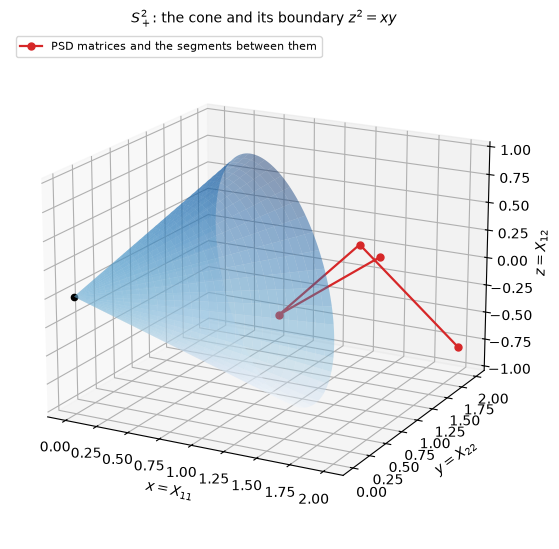

In [11]:
# boundary of the cone: x + y = s, (x - y)^2 + 4 z^2 = s^2, so with s >= 0 and
# x = s(1 + cos(phi))/2, y = s(1 - cos(phi))/2, z = s sin(phi)/2 we get xy = z^2
ss = np.linspace(0.0, 2.0, 121)
pp = np.linspace(0.0, 2 * np.pi, 181)
SS, PP = np.meshgrid(ss, pp)
Xc = SS * (1 + np.cos(PP)) / 2
Yc = SS * (1 - np.cos(PP)) / 2
Zc = SS * np.sin(PP) / 2
assert np.allclose(Xc * Yc, Zc ** 2, atol=1e-12)          # the surface is z^2 = xy
assert Xc.min() >= 0 and Yc.min() >= 0

mats = [np.array([[1.8, 0.3], [0.3, 1.1]]),
        np.array([[0.8, -0.55], [-0.55, 1.5]]),
        np.array([[1.2, 0.0], [0.0, 2.0]]),
        np.array([[2.0, -0.8], [-0.8, 2.0]])]
pts = np.array([[M[0, 0], M[1, 1], M[0, 1]] for M in mats])
print("marked matrices, eigenvalues:", np.round(np.linalg.eigvalsh(np.array(mats)), 3).tolist())

fig = plt.figure(figsize=(8.6, 6.6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(Xc, Yc, Zc, cmap="Blues", alpha=0.45, linewidth=0,
                rstride=4, cstride=4)
ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], "o-", color="C3", ms=5, lw=1.6,
        label="PSD matrices and the segments between them")
ax.plot([0.0], [0.0], [0.0], "k.", ms=9)
ax.set_xlabel("$x = X_{11}$"); ax.set_ylabel("$y = X_{22}$")
ax.set_zlabel("$z = X_{12}$")
ax.set_title("$S^2_+$: the cone and its boundary $z^2 = xy$", fontsize=10)
ax.view_init(elev=18, azim=-62)
ax.legend(loc="upper left", fontsize=8)
plt.show()

In [12]:
def rand_psd(n, rng=rng):
    """n random PSD matrices G G^T with G gaussian."""
    G = rng.normal(size=(n, 2, 2))
    return G @ np.transpose(G, (0, 2, 1))


n = 200_000
P, Q = rand_psd(n), rand_psd(n)
lam = rng.uniform(0.0, 1.0, size=n)
R = lam[:, None, None] * P + (1 - lam)[:, None, None] * Q
min_eig = np.linalg.eigvalsh(R)[:, 0]
print(f"min eigenvalue over {n} convex combinations of PSD matrices: {min_eig.min():.3e}")
assert min_eig.min() >= -1e-12

alpha = rng.uniform(0.0, 10.0, size=n)
assert np.linalg.eigvalsh(alpha[:, None, None] * P)[:, 0].min() >= -1e-12
print("min eigenvalue over the same matrices scaled by alpha >= 0:",
      f"{np.linalg.eigvalsh(alpha[:, None, None] * P)[:, 0].min():.3e}")

# the definition x^T X x >= 0, checked against the eigenvalues
X = P[0]
v = rng.normal(size=(100_000, 2))
q = np.einsum("ni,ij,nj->n", v, X, v)
print("min of v^T X v:", f"{q.min():.3e}", " smallest eigenvalue of X:", f"{np.linalg.eigvalsh(X)[0]:.3e}")
assert q.min() >= -1e-12

# segments between the marked matrices stay inside
for i in range(len(mats)):
    for j in range(i + 1, len(mats)):
        s = np.linspace(0.0, 1.0, 201)
        seg = s[:, None, None] * mats[i] + (1 - s)[:, None, None] * mats[j]
        assert np.linalg.eigvalsh(seg)[:, 0].min() >= -1e-12
print("all 6 segments between the marked matrices are PSD")

min eigenvalue over 200000 convex combinations of PSD matrices: 9.286e-05


min eigenvalue over the same matrices scaled by alpha >= 0: 4.214e-12
min of v^T X v: 9.614e-06  smallest eigenvalue of X: 3.819e-01
all 6 segments between the marked matrices are PSD


max radius sqrt((x-1/2)^2 + z^2) on the cut: 0.500000000000
max (x-1/2)^2 + z^2 over random trace-1 PSD matrices: 0.250000000000
identity det X = 1/4 - (x-1/2)^2 - z^2 checked, max deviation 1.94e-16


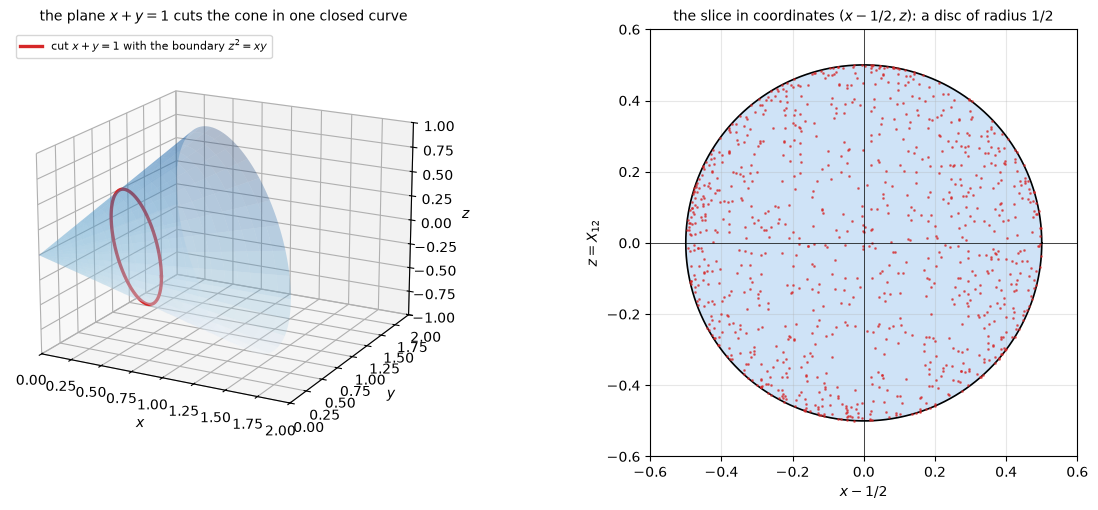

In [13]:
# boundary of the slice: x + y = 1 and z^2 = xy, parametrised by the angle
th = np.linspace(0.0, 2 * np.pi, 2001)
x_s = 0.5 + 0.5 * np.cos(th)
y_s = 0.5 - 0.5 * np.cos(th)
z_s = 0.5 * np.sin(th)
assert np.allclose(x_s + y_s, 1.0)
assert np.allclose(z_s ** 2, x_s * y_s, atol=1e-12)
rho = np.hypot(x_s - 0.5, z_s)
print("max radius sqrt((x-1/2)^2 + z^2) on the cut:", f"{rho.max():.12f}")

# random PSD matrices with trace 1: G G^T / tr(G G^T)
n2 = 200_000
G = rng.normal(size=(n2, 2, 2))
S = G @ np.transpose(G, (0, 2, 1))
S = S / np.trace(S, axis1=1, axis2=2)[:, None, None]
t_s, z_r = S[:, 0, 0] - 0.5, S[:, 0, 1]
r2 = t_s ** 2 + z_r ** 2
print("max (x-1/2)^2 + z^2 over random trace-1 PSD matrices:", f"{r2.max():.12f}")
assert r2.max() <= 0.25 + 1e-12
assert np.allclose(0.25 - r2, np.linalg.det(S), atol=1e-12)   # det = 1/4 - t^2 - z^2
print("identity det X = 1/4 - (x-1/2)^2 - z^2 checked, max deviation",
      f"{np.abs(0.25 - r2 - np.linalg.det(S)).max():.2e}")

fig = plt.figure(figsize=(12.5, 5.2))
ax = fig.add_subplot(121, projection="3d")
ax.plot_surface(Xc, Yc, Zc, cmap="Blues", alpha=0.28, linewidth=0,
                rstride=6, cstride=6)
ax.plot(x_s, y_s, z_s, color="C3", lw=2.4,
        label="cut $x+y=1$ with the boundary $z^2=xy$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_zlabel("$z$")
ax.set_title("the plane $x+y=1$ cuts the cone in one closed curve", fontsize=10)
ax.view_init(elev=18, azim=-62)
ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_zlim(-1, 1)
ax.legend(loc="upper left", fontsize=8)

ax = fig.add_subplot(122)
ax.add_patch(plt.Circle((0.0, 0.0), 0.5, color="#cfe3f7", zorder=0))
ax.plot(x_s - 0.5, z_s, "k-", lw=1.2)
ax.plot(t_s[::200], z_r[::200], ".", ms=2, color="C3", alpha=0.6)
ax.axhline(0.0, color="k", lw=0.5); ax.axvline(0.0, color="k", lw=0.5)
ax.set_aspect("equal"); ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("$x-1/2$"); ax.set_ylabel("$z = X_{12}$")
ax.set_title("the slice in coordinates $(x-1/2, z)$: a disc of radius $1/2$", fontsize=10)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [14]:
def rand_det_ge1(n, rng=rng):
    """Random PSD matrices with det >= 1: R diag(e^u, e^v) R^T, u + v >= 0."""
    u = rng.uniform(-1.5, 1.5, size=n)
    v = -u + rng.uniform(0.0, 3.0, size=n)
    th = rng.uniform(0.0, np.pi, size=n)
    c, s = np.cos(th), np.sin(th)
    Rm = np.zeros((n, 2, 2))
    Rm[:, 0, 0], Rm[:, 0, 1] = c, -s
    Rm[:, 1, 0], Rm[:, 1, 1] = s, c
    D = np.zeros((n, 2, 2))
    D[:, 0, 0], D[:, 1, 1] = np.exp(u), np.exp(v)
    return Rm @ D @ np.transpose(Rm, (0, 2, 1))


n3 = 400_000
P, Q = rand_det_ge1(n3), rand_det_ge1(n3)
lam = rng.uniform(0.0, 1.0, size=n3)
R = lam[:, None, None] * P + (1 - lam)[:, None, None] * Q
dets = np.linalg.det(R)
m_eig = np.linalg.eigvalsh(R)[:, 0]
print(f"det P, det Q >= 1: {np.linalg.det(P).min():.6f}, {np.linalg.det(Q).min():.6f}")
print(f"min det over {n3} convex combinations: {dets.min():.12f}")
print(f"min eigenvalue over the same combinations: {m_eig.min():.12f}")
assert dets.min() >= 1.0 - 1e-9 and m_eig.min() >= -1e-9

# the reason: sqrt(det) is concave on S^2_+
lhs = np.sqrt(dets)
rhs = lam * np.sqrt(np.linalg.det(P)) + (1 - lam) * np.sqrt(np.linalg.det(Q))
print(f"min slack in sqrt(det(lam P + (1-lam) Q)) >= lam sqrt(det P) + (1-lam) sqrt(det Q):"
      f" {np.min(lhs - rhs):.3e}")
assert np.min(lhs - rhs) >= -1e-12
print(f"and sqrt(det) >= 1 on the combination, smallest value: {lhs.min():.6f}")

# contrast: {det X <= 1} is not convex
Pc, Qc = np.diag([2.0, 0.4]), np.diag([0.4, 2.0])
mid = 0.5 * (Pc + Qc)
print("\ndet(diag(2,0.4)) =", np.linalg.det(Pc), " det(diag(0.4,2)) =", np.linalg.det(Qc),
      " det(midpoint) =", np.linalg.det(mid))
assert np.linalg.det(Pc) <= 1 and np.linalg.det(Qc) <= 1 and np.linalg.det(mid) > 1

# which points have a zero eigenvalue: the boundary, det = 0
ub = rng.uniform(0.0, np.sqrt(2.0), size=100_000)
vb = rng.uniform(0.0, np.sqrt(2.0), size=100_000)
Bnd = np.zeros((100_000, 2, 2))
Bnd[:, 0, 0], Bnd[:, 1, 1] = ub ** 2, vb ** 2
Bnd[:, 0, 1] = Bnd[:, 1, 0] = ub * vb
zero_eig = np.abs(np.linalg.eigvalsh(Bnd)[:, 0])
print("\nmax |smallest eigenvalue| on the boundary surface:", f"{zero_eig.max():.3e}")
interior = np.linalg.eigvalsh(np.vstack([P, Q]))[:, 0].min()
print("min smallest eigenvalue over the sampled matrices with det >= 1:", f"{interior:.6f}")
w, V = np.linalg.eigh(np.array([[1.0, 1.0], [1.0, 1.0]]))
print("X = [[1,1],[1,1]]: eigenvalues", np.round(w, 12), " eigenvector of 0:", np.round(V[:, 0], 6))

det P, det Q >= 1: 1.000001, 1.000005
min det over 400000 convex combinations: 1.004249515513
min eigenvalue over the same combinations: 0.224250368511
min slack in sqrt(det(lam P + (1-lam) Q)) >= lam sqrt(det P) + (1-lam) sqrt(det Q): 1.760e-09
and sqrt(det) >= 1 on the combination, smallest value: 1.002123

det(diag(2,0.4)) = 0.8  det(diag(0.4,2)) = 0.8  det(midpoint) = 1.44

max |smallest eigenvalue| on the boundary surface: 3.331e-16
min smallest eigenvalue over the sampled matrices with det >= 1: 0.223131
X = [[1,1],[1,1]]: eigenvalues [0. 2.]  eigenvector of 0: [-0.707107  0.707107]


### Explain

**$S^n_+$ is convex [CO 4.9].** For $P,Q\succeq0$ and $\lambda\in[0,1]$,
$x^T(\lambda P+(1-\lambda)Q)x=\lambda\,x^TPx+(1-\lambda)\,x^TQx\ge0$, so the
convex combination is PSD. Numerically, the smallest eigenvalue over 200 000
random convex combinations was $9.286\times10^{-5}$, never negative, and $v^TXv$
stayed $\ge9.614\times10^{-6}$ over $10^5$ random $v$ for the sampled $X$ whose
smallest eigenvalue is $0.3819$. All 6 segments between the marked matrices in
the plot were PSD.

**Why it is a cone.** The same computation with $\alpha,\beta\ge0$,
$x^T(\alpha P+\beta Q)x=\alpha\,x^TPx+\beta\,x^TQx\ge0$, shows that $S^n_+$ is
closed under conic combinations. Scaling 200 000 PSD matrices by
$\alpha\in[0,10]$ gave smallest eigenvalue $4.214\times10^{-12}$, i.e. $0$ up to
rounding. It is a cone and not a subspace: $P\succeq0$ and $-P\succeq0$ force
$P=0$.

**Where the eigenvalue $0$ sits.** Since $\det X=xy-z^2$, the determinant
vanishes exactly on the boundary surface $z^2=xy$, on the two edges
$(x,z)=(0,0)$ and $(y,z)=(0,0)$, and at the apex. Those are the rank-1 points:
one eigenvalue is $0$ (the maximum of $|\lambda_{\min}|$ over 100 000 boundary
samples was $3.331\times10^{-16}$) and the other is $\operatorname{tr}X=x+y$, so
$X=\begin{pmatrix}1&1\\1&1\end{pmatrix}$ has eigenvalues $0$ and $2$ with null
vector $(1,-1)/\sqrt2$. Interior points have $\det X>0$ and both eigenvalues
positive: the sampled matrices with $\det X\ge1$ had smallest eigenvalue at
least $0.223131$. On the slice $\operatorname{tr}X=1$ the boundary
$\det X=0$ is the circle $(x-1/2)^2+z^2=1/4$ (measured radius
$0.500000000000$), because there $\det X=1/4-(x-1/2)^2-z^2$ exactly (largest
deviation $1.94\times10^{-16}$).

**Is $\{X\succeq0,\ \det X\ge1\}$ convex? Yes.** On $S^n_+$ the function
$X\mapsto(\det X)^{1/2}$ is concave, so

$$(\det(\lambda P+(1-\lambda)Q))^{1/2}\ \ge\
\lambda(\det P)^{1/2}+(1-\lambda)(\det Q)^{1/2}\ \ge\ 1$$

whenever $\det P,\det Q\ge1$, and the PSD condition is preserved as above. Over
400 000 random convex combinations the smallest determinant was
$1.004249515513$ and the smallest eigenvalue $0.224250368511$: no violation,
the concavity slack was never below $1.760\times10^{-9}$, and
$(\det X)^{1/2}\ge1.002123$ throughout. The inequality cannot be reversed:
$\operatorname{diag}(2,0.4)$ and $\operatorname{diag}(0.4,2)$ both have
determinant $0.8\le1$, but the midpoint $\operatorname{diag}(1.2,1.2)$ has
determinant $1.44>1$, so $\{\det X\le1\}$ is not convex.